# 01 · EDA (tabular) — restarted for the dual-source design

**What changed.** The first audit asked "can the CT Colonography labels support benign-vs-malignant?". The answer was mostly no
(3 cancers). The approved design therefore draws the **malignant** class mainly from *StageII-Colorectal-CT* and the **benign** class from
*CT Colonography*, which makes **class and data source the same thing**. This notebook restarts the EDA around that fact: every section
asks what differs between the two sources besides the disease.

**Run order:** `python src/build_polyp_table.py` → this notebook. Outputs: figures in `reports/figures/eda_*.png`, tables in `reports/tables/*.csv`.

### Where each section goes in the paper (Chapter 4)
| Notebook section | Paper section | Status |
|---|---|---|
| 1 · Role of every patient | **4.2** Data description | ready |
| 2 · StageII vs CTC comparison (table + figure) | **4.2** (and motivates **4.4** checks) | ready (metadata level) |
| 3 · CTC labels: histology, size, segment | **4.2** | ready |
| 4 · Slice-label coverage | **4.2** | ready |
| 5 · Missingness and cleaning-decision log | **4.2** | ready |
| 6 · What we must download | **4.2** / appendix | ready |
| 7 · Precision planning (CI vs test positives) | **4.4** / **4.5** | ready |
| `02_eda_images.ipynb` | **4.2** (image properties), **4.4** (before/after harmonisation) | needs the DICOM download |

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIG, TAB = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

polyps   = pd.read_parquet(ROOT / "data/processed/polyps.parquet")
patients = pd.read_parquet(ROOT / "data/processed/patients.parquet")
series   = pd.read_parquet(ROOT / "data/processed/series.parquet")
stage2   = pd.read_parquet(ROOT / "data/processed/stage2.parquet")

# --- look & feel: white surface, thin marks, quiet grid, ink-coloured text ------------------------------------
INK, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#ffffff"
BLUE, ORANGE, GRAY, LGRAY = "#2a78d6", "#eb6834", "#9b9a95", "#c9c8c3"
CLASS_COLOR = {"non_malignant": BLUE, "malignant": ORANGE, "other_or_na": GRAY}
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110})

def tidy(ax, grid="x"):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(GRID); ax.spines["bottom"].set_color(GRID)
    if grid: ax.grid(axis=grid, color=GRID, lw=0.8); ax.set_axisbelow(True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

# --- roles: what each CTC patient is used for under the approved design ---------------------------------------
def role(r):
    if r.label_status == "not_in_any_label_file": return "CTC unlabelled"
    if r.n_polyps == 0:                            return "CTC no polyp"
    return "CTC cancer" if r.n_malignant > 0 else "CTC benign class"
patients["role"] = patients.apply(role, axis=1)
polyps["advanced"] = (polyps.size_mm >= 10) | polyps.histology_code.isin([14, 15, 16]) | (polyps.histology_class == "malignant")

# volume series only (not scouts/topograms)
vol = series[~series.is_localizer].copy()
# sex: clinical TSV first, digest as fallback ('U'/'O' = unknown/other -> missing)
sex_dig = patients.sex_digest.map({"M": "Male", "F": "Female"})
patients["sex"] = patients.sex_clinical.fillna(sex_dig)
# implausible ages (e.g. 9, 105, 110) -> missing
patients["age"] = patients.age_years.where(patients.age_years.between(18, 100))

R = patients.role.value_counts()
print(R.to_string()); print("total CTC", R.sum(), "| StageII", len(stage2))

role
CTC unlabelled      480
CTC no polyp        242
CTC benign class    100
CTC cancer            3
total CTC 825 | StageII 230


## 1 · Role of every patient &nbsp; → **Paper §4.2** (Data description)

Under the approved design the classification task uses three groups. Everyone else can only help in other ways.

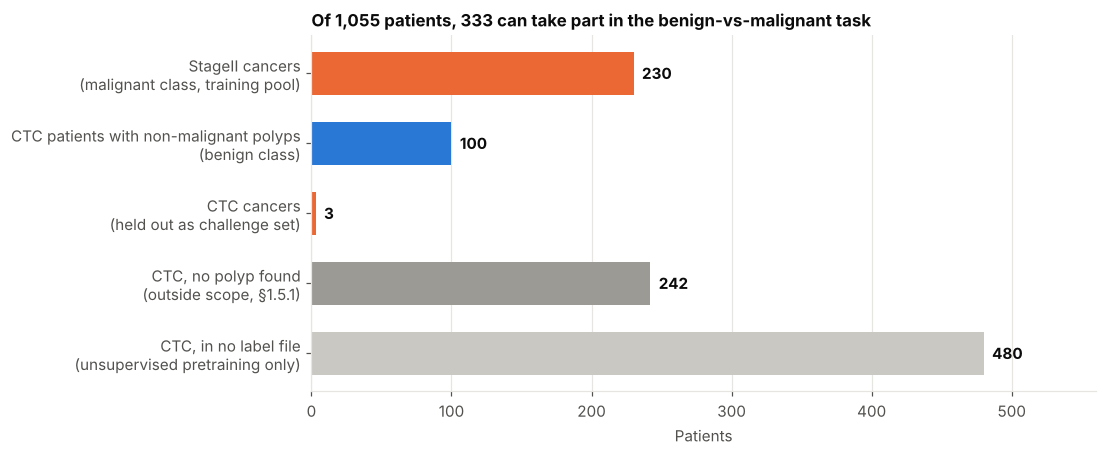

,patients
StageII cancers,230
CTC benign class,100
CTC cancers,3
CTC no polyp,242
CTC unlabelled,480


In [2]:
n_s2, n_ben, n_can = len(stage2), int(R["CTC benign class"]), int(R["CTC cancer"])
n_nop, n_unl = int(R["CTC no polyp"]), int(R["CTC unlabelled"])
rows = [("StageII cancers\n(malignant class, training pool)", n_s2, ORANGE),
        ("CTC patients with non-malignant polyps\n(benign class)", n_ben, BLUE),
        ("CTC cancers\n(held out as challenge set)", n_can, ORANGE),
        ("CTC, no polyp found\n(outside scope, §1.5.1)", n_nop, GRAY),
        ("CTC, in no label file\n(unsupervised pretraining only)", n_unl, LGRAY)]
fig, ax = plt.subplots(figsize=(9.2, 4.2))
y = np.arange(len(rows))[::-1]
ax.barh(y, [r[1] for r in rows], height=0.62, color=[r[2] for r in rows])
for yi, r in zip(y, rows): ax.text(r[1] + 6, yi, f"{r[1]:,}", va="center", fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels([r[0] for r in rows]); ax.set_xlim(0, 560); ax.set_xlabel("Patients")
ax.set_title(f"Of {n_s2 + len(patients):,} patients, {n_s2 + n_ben + n_can} can take part in the benign-vs-malignant task")
tidy(ax, "x"); save(fig, "eda_01_patient_roles")

role_tab = pd.DataFrame({"patients": [n_s2, n_ben, n_can, n_nop, n_unl]},
    index=["StageII cancers", "CTC benign class", "CTC cancers", "CTC no polyp", "CTC unlabelled"])
role_tab.to_csv(TAB / "eda_01_patient_roles.csv"); display(role_tab)

**Reading it.** The malignant class is almost entirely StageII (230 of 233 cancers), the benign class entirely CTC (100 patients). Two CTC patients in the benign
group are listed in two label files and are flagged until resolved. The 480 unlabelled CTC patients cannot be used for supervised training but are a legitimate pool
for the unsupervised DenseCL step (§3.4.3.1), provided they stay on the training side of the split.

## 2 · StageII vs CTC: what differs besides the disease? &nbsp; → **Paper §4.2**, motivates **§4.4**

Everything in this table is a candidate shortcut: if a model can read it from the pixels, it can classify without looking at the lesion.
Metadata-level only; the DICOM headers (slice thickness, spacing, intensities) are checked in `02_eda_images.ipynb`.

In [3]:
ben_ids = patients.loc[patients.role == "CTC benign class", "patient_id"]
ben_vol = vol[vol.patient_id.isin(ben_ids)]
ben = patients[patients.role == "CTC benign class"]
s2 = stage2.assign(age=stage2.age_years.where(stage2.age_years.between(18, 100)))

def iqr(x): return f"{x.median():.0f} ({x.quantile(.25):.0f}–{x.quantile(.75):.0f})"
pct_male = lambda s: f"{(s == 'Male').sum() / s.notna().sum():.0%} of {s.notna().sum()}"
top = lambda s, k=3: "; ".join(f"{m} ×{n}" for m, n in s.value_counts().head(k).items())
yrs = lambda d: f"{d.min().year}–{d.max().year} (n={d.notna().sum()})"
ben_dates = series[series.patient_id.isin(ben_ids)].groupby("patient_id").study_date.min().dropna()

cmp = pd.DataFrame({
 "StageII-Colorectal-CT (malignant class)": [
    len(s2), "1", iqr(s2.image_count), "5 mm (TCIA page; confirm in DICOM)",
    top(s2.manufacturer), top(s2.model, 4),
    yrs(s2.study_date), iqr(s2.age), pct_male(s2.sex.map({"M": "Male", "F": "Female"})),
    f"{(s2.body_part == 'PELVIS').sum()} pelvis, {(s2.body_part == 'ABDOMEN').sum()} abdomen",
    "Routine IV-contrast CT within 10 days before surgery", "none (patient-level 'stage II cancer' only)"],
 "CT Colonography (benign class)": [
    len(ben), f"{ben_vol.groupby('patient_id').size().median():.0f} volumes (prone/supine)", iqr(ben_vol.image_count),
    "≈1 mm (series names; confirm in DICOM)",
    top(series[series.patient_id.isin(ben_ids)].manufacturer), top(series[series.patient_id.isin(ben_ids)].model, 4),
    yrs(ben_dates) + " — most dates masked", iqr(ben.age), pct_male(ben.sex),
    "colon-specific volumes",
    "Bowel prep, air insufflation, oral tagging (barium/iodine)", "polyp slice numbers for part of the cohort"]},
 index=["Patients", "Series per patient (median)", "Images per volume, median (IQR)", "Slice thickness",
        "Vendors", "Scanner models", "Study years (visible)", "Age, median (IQR)", "Sex",
        "Body coverage", "Acquisition", "Lesion annotations"])
cmp.to_csv(TAB / "eda_02_stage2_vs_ctc.csv"); display(cmp)

,StageII-Colorectal-CT (malignant class),CT Colonography (benign class)
Patients,230,100
Series per patient (median),1,2 volumes (prone/supine)
"Images per volume, median (IQR)",56 (51–61),538 (501–574)
Slice thickness,5 mm (TCIA page; confirm in DICOM),≈1 mm (series names; confirm in DICOM)
Vendors,SIEMENS ×198; Philips ×32,SIEMENS ×154; GE MEDICAL SYSTEMS ×59; Philips ×17
Scanner models,Sensation 64 ×178; Brilliance 64 ×32; Sensatio...,Sensation 64 ×84; Sensation 16 ×70; LightSpeed...
Study years (visible),2003–2009 (n=230),2005–2006 (n=40) — most dates masked
"Age, median (IQR)",60 (51–68),60 (53–65)
Sex,57% of 230,67% of 100
Body coverage,"110 pelvis, 120 abdomen",colon-specific volumes


/tmp/ipykernel_397/3754540329.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = a.boxplot([g[1] for g in groups], vert=False, widths=0.5, showfliers=True, patch_artist=True,


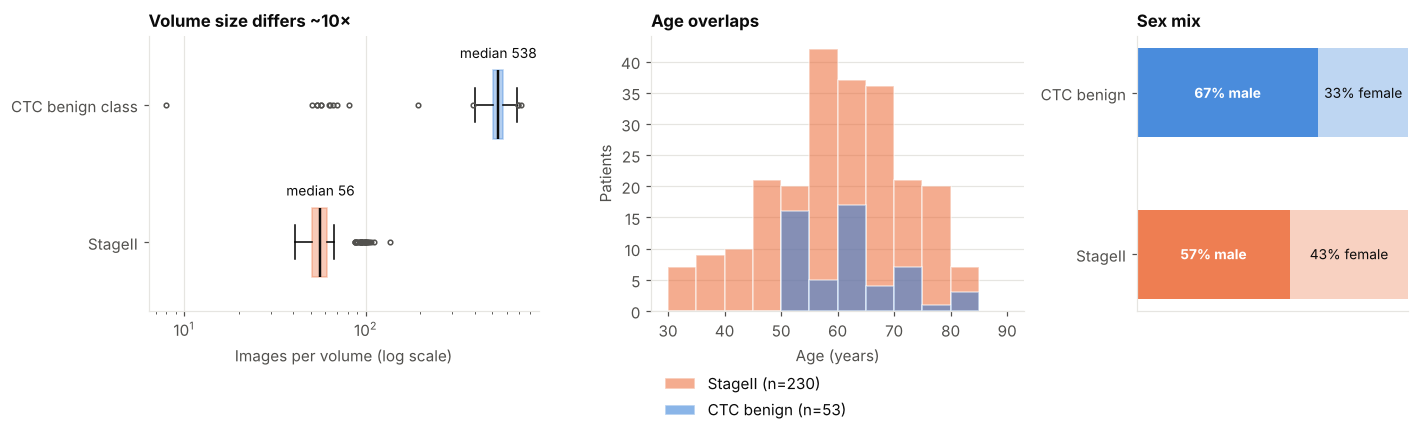

age tests: StageII median 60, CTC benign median 60


In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.15, 1.1, 0.8]})
# (a) images per volume (log scale)
a = axs[0]
groups = [("StageII", s2.image_count.dropna(), ORANGE), ("CTC benign class", ben_vol.image_count.dropna(), BLUE)]
bp = a.boxplot([g[1] for g in groups], vert=False, widths=0.5, showfliers=True, patch_artist=True,
               medianprops=dict(color=INK, lw=1.6), flierprops=dict(marker="o", ms=3, mfc="none", mec=MUTED))
for patch, g in zip(bp["boxes"], groups): patch.set(facecolor=g[2], alpha=0.35, edgecolor=g[2])
a.set_yticklabels([g[0] for g in groups]); a.set_xscale("log"); a.set_xlabel("Images per volume (log scale)")
for yi, g in enumerate(groups, start=1): a.text(g[1].median(), yi + 0.34, f"median {g[1].median():.0f}", ha="center", color=INK, fontsize=9)
a.set_title("Volume size differs ~10×"); tidy(a, "x")
# (b) age
b = axs[1]; bins = np.arange(30, 95, 5)
b.hist(s2.age.dropna(), bins=bins, color=ORANGE, alpha=0.55, label=f"StageII (n={s2.age.notna().sum()})", edgecolor=SURF)
b.hist(ben.age.dropna(), bins=bins, color=BLUE, alpha=0.55, label=f"CTC benign (n={ben.age.notna().sum()})", edgecolor=SURF)
b.set_xlabel("Age (years)"); b.set_ylabel("Patients"); b.legend(loc="upper left", bbox_to_anchor=(0.0, -0.18), ncol=1); b.set_title("Age overlaps"); tidy(b, "y")
# (c) sex share
c = axs[2]
for i, (nm, s, col) in enumerate([("StageII", s2.sex.map({"M": "Male", "F": "Female"}), ORANGE), ("CTC benign", ben.sex, BLUE)]):
    s = s.dropna(); m = (s == "Male").mean()
    c.barh(i, m, color=col, height=0.55, alpha=0.85); c.barh(i, 1 - m, left=m, color=col, height=0.55, alpha=0.3)
    c.text(m / 2, i, f"{m:.0%} male", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    c.text(m + (1 - m) / 2, i, f"{1 - m:.0%} female", ha="center", va="center", color=INK, fontsize=9)
c.set_yticks([0, 1]); c.set_yticklabels(["StageII", "CTC benign"]); c.set_xlim(0, 1); c.set_xticks([])
c.set_title("Sex mix"); tidy(c, None)
fig.tight_layout(); save(fig, "eda_02_source_confounding")
print(f"age tests: StageII median {s2.age.median():.0f}, CTC benign median {ben.age.median():.0f}")

**Reading it.** The classes are separated by *how the scan was acquired* more than by who the patients are: one thick-slice contrast-enhanced series of about 57 images
against two thin-slice colon volumes of roughly 540 images each. Age and sex overlap reasonably, so demographics are a smaller worry than acquisition. This is the
justification for the harmonisation steps in §4.1 and for the source-prediction check in §4.4: if a simple model can tell the sources apart from the images alone, the
classification score cannot be read as evidence of cancer detection.

## 3 · CTC labels: what are the polyps? &nbsp; → **Paper §4.2**

Histology codes follow the key image (x.5). Our grouping — **1–9 malignant, 10–17 non-malignant, 88/98 other** — is an interpretation to confirm.

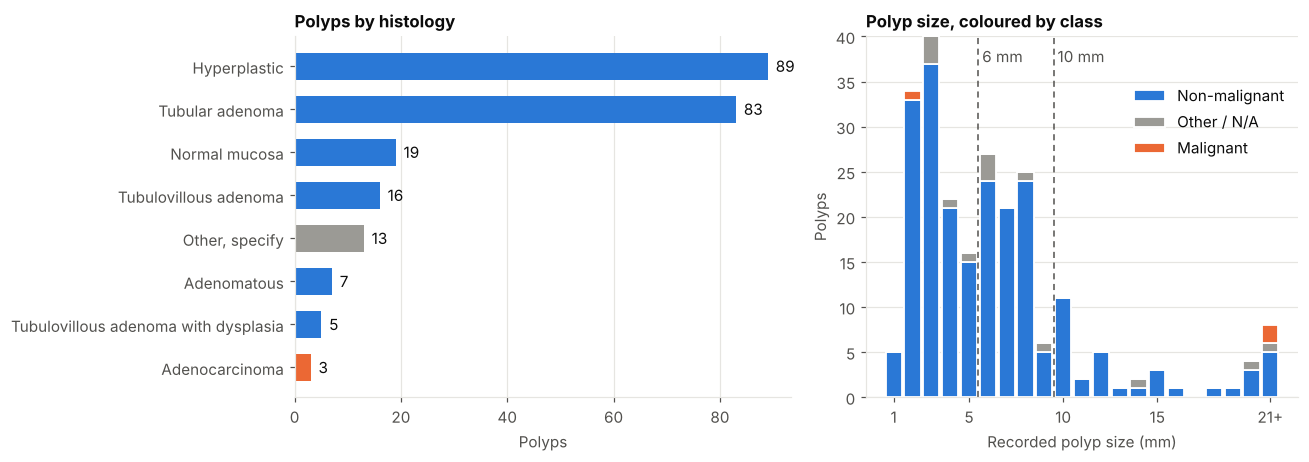

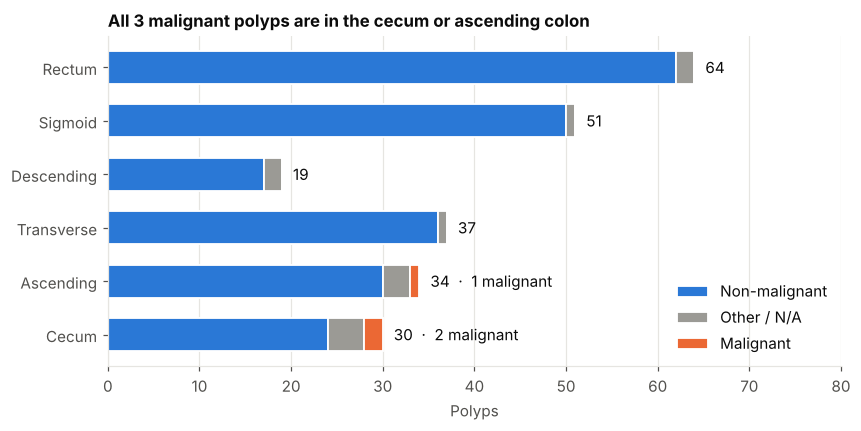

235 polyps | malignant 3 | ≤5 mm 117 | ≥6 mm 118 | non-malignant ≥6 mm 108
median size (mm): {'malignant': 30.0, 'non_malignant': 5.0, 'other_or_na': 6.0}


In [5]:
order = (polyps.groupby(["histology_code", "histology", "histology_class"]).size()
         .reset_index(name="n").sort_values("n", ascending=True))
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.15, 1]})
a.barh(order.histology, order.n, height=0.62, color=order.histology_class.map(CLASS_COLOR))
for yi, n in enumerate(order.n): a.text(n + 1.5, yi, str(n), va="center", color=INK)
a.set_title("Polyps by histology"); a.set_xlabel("Polyps"); tidy(a, "x")
SHORT = {"non_malignant": "Non-malignant", "malignant": "Malignant", "other_or_na": "Other / N/A"}
edges = np.arange(0.5, 22.5, 1.0); bottom = np.zeros(len(edges) - 1)
for c in ["non_malignant", "other_or_na", "malignant"]:
    h, _ = np.histogram(np.clip(polyps.loc[polyps.histology_class == c, "size_mm"], 1, 21), bins=edges)
    b.bar(edges[:-1] + 0.5, h, width=0.86, bottom=bottom, color=CLASS_COLOR[c], label=SHORT[c], edgecolor=SURF, linewidth=1.2); bottom += h
for x, lab in [(5.5, "6 mm"), (9.5, "10 mm")]:
    b.axvline(x, color=MUTED, lw=1, ls=(0, (4, 3))); b.text(x + 0.2, bottom.max() * 0.97, lab, color=MUTED, va="top")
b.set_xticks([1, 5, 10, 15, 21]); b.set_xticklabels(["1", "5", "10", "15", "21+"])
b.set_xlabel("Recorded polyp size (mm)"); b.set_ylabel("Polyps"); b.set_title("Polyp size, coloured by class")
b.legend(loc="upper right", bbox_to_anchor=(1.0, 0.9)); tidy(b, "y")
fig.tight_layout(); save(fig, "eda_03_histology_and_size")

seg_order = ["Rectum", "Sigmoid", "Descending", "Transverse", "Ascending", "Cecum"]
ct = pd.crosstab(polyps.segment, polyps.histology_class).reindex(seg_order).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8.6, 3.9)); y = np.arange(6)[::-1]; left = np.zeros(6)
for c in ["non_malignant", "other_or_na", "malignant"]:
    v = ct[c].to_numpy(); ax.barh(y, v, left=left, height=0.62, color=CLASS_COLOR[c], label=SHORT[c], edgecolor=SURF, linewidth=1.2); left += v
for yi, s in zip(y, seg_order):
    ax.text(left[seg_order.index(s)] + 1.2, yi, f"{int(ct.loc[s].sum())}" + (f"  ·  {int(ct.loc[s,'malignant'])} malignant" if ct.loc[s, 'malignant'] else ""), va="center")
ax.set_yticks(y); ax.set_yticklabels(seg_order); ax.set_xlim(0, 80); ax.set_xlabel("Polyps")
ax.set_title("All 3 malignant polyps are in the cecum or ascending colon"); ax.legend(loc="lower right"); tidy(ax, "x")
save(fig, "eda_03_segment_by_class")
ct.to_csv(TAB / "eda_03_segment_by_class.csv")
print(f"{len(polyps)} polyps | malignant {(polyps.histology_class=='malignant').sum()} | ≤5 mm {(polyps.size_mm<=5).sum()} | ≥6 mm {(polyps.size_mm>=6).sum()} "
      f"| non-malignant ≥6 mm {((polyps.size_mm>=6)&(polyps.histology_class=='non_malignant')).sum()}")
print("median size (mm):", polyps.groupby("histology_class").size_mm.median().to_dict())

**Reading it.** 3 of 235 polyps are malignant (1.3 %); the rest are mainly hyperplastic polyps and adenomas. Half of all polyps are ≤ 5 mm. The cancers are the largest polyps and are all right-sided,
so size and location are shortcuts available inside CTC as well. Report these baselines next to the CNN results in §4.4.

## 4 · Can we locate the polyp? Slice-label coverage &nbsp; → **Paper §4.2**

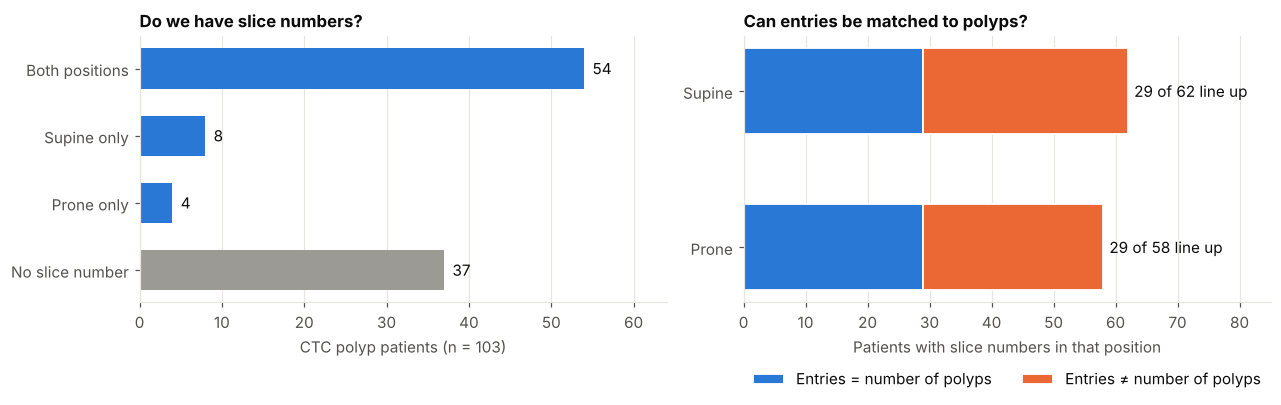

StageII lesion annotations in digest: none (Annotations Flag empty for all 230)


In [6]:
per_pat = polyps.groupby("patient_id").agg(n_polyps=("polyp_id", "size"),
                                            supine=("supine_slices_patient", "first"), prone=("prone_slices_patient", "first"))
n_entries = lambda x: 0 if pd.isna(x) else len(str(x).split("/"))
pp = per_pat.assign(has_sup=per_pat.supine.notna(), has_pro=per_pat.prone.notna())
cov = pd.Series({"Both positions": int((pp.has_sup & pp.has_pro).sum()), "Supine only": int((pp.has_sup & ~pp.has_pro).sum()),
                 "Prone only": int((~pp.has_sup & pp.has_pro).sum()), "No slice number": int((~pp.has_sup & ~pp.has_pro).sum())})
match = {}
for pos, col in [("Supine", "supine"), ("Prone", "prone")]:
    has = pp[col].notna(); eq = pp.loc[has, col].map(n_entries) == pp.loc[has, "n_polyps"]
    match[pos] = (int(eq.sum()), int((~eq).sum()))
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.9))
a.barh(cov.index[::-1], cov.values[::-1], height=0.6, color=[BLUE, BLUE, BLUE, GRAY][::-1])
for yi, v in enumerate(cov.values[::-1]): a.text(v + 1, yi, str(v), va="center")
a.set_xlim(0, 64); a.set_xlabel(f"CTC polyp patients (n = {len(pp)})"); a.set_title("Do we have slice numbers?"); tidy(a, "x")
for yi, pos in zip([1, 0], ["Supine", "Prone"]):
    ok, bad = match[pos]
    b.barh(yi, ok, height=0.55, color=BLUE, edgecolor=SURF, linewidth=1.2, label="Entries = number of polyps" if yi == 1 else None)
    b.barh(yi, bad, left=ok, height=0.55, color=ORANGE, edgecolor=SURF, linewidth=1.2, label="Entries ≠ number of polyps" if yi == 1 else None)
    b.text(ok + bad + 1, yi, f"{ok} of {ok + bad} line up", va="center")
b.set_yticks([1, 0]); b.set_yticklabels(["Supine", "Prone"]); b.set_xlim(0, 85)
b.set_xlabel("Patients with slice numbers in that position"); b.set_title("Can entries be matched to polyps?")
b.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2); tidy(b, "x")
fig.tight_layout(); save(fig, "eda_04_slice_label_coverage")
print("StageII lesion annotations in digest: none (Annotations Flag empty for all 230)")

**Reading it.** 37 of 103 CTC polyp patients have no slice number, and where slice numbers exist they line up with the polyp count for only about half the patients. StageII has no
lesion information at all. Lesion localisation therefore needs a radiologist or an automated colon-region step, which is stated as a limitation in §4.5.

## 5 · Missingness and cleaning-decision log &nbsp; → **Paper §4.2**

Every row is a decision a reader of the paper may ask about. Counts are computed here, not typed.

In [7]:
conf = patients[patients.label_status.str.startswith("CONFLICT")].patient_id.tolist()
n_empty_slots = 1227 - len(polyps)   # lesion slots in the wide sheets minus real polyps (see build script)
pos_unknown = int((vol.position == "unknown").sum())
log = pd.DataFrame([
 ("CTC patients in no label file", f"{n_unl}", "Excluded from supervised work; kept for unsupervised pretraining (training side of the split only)."),
 ("Patients listed in two label files", f"{len(conf)} ({', '.join(c[-4:] for c in conf)})", "Flagged; excluded from every split until resolved with the data providers."),
 ("Empty lesion slots pre-filled with 'removed in pieces = No'", f"{n_empty_slots}", "Dropped: a real polyp needs a segment, size, size source or histology."),
 ("Polyps with histology 'Other' or 'Not applicable'", f"{int((polyps.histology_class == 'other_or_na').sum())}", "Kept in the polyp table; excluded from class labels."),
 ("Cancer recorded as 2 mm (patient …4.0272)", "1", "Kept as malignant; flagged as a probable data-entry error to query."),
 ("CTC polyp patients with no slice number", f"{int((~pp.has_sup & ~pp.has_pro).sum())} of {len(pp)}", "Polyp needs manual localisation (radiologist) or the patient is excluded from patch-level work."),
 ("CTC volume series with unknown prone/supine position", f"{pos_unknown} of {len(vol)}", "Resolve from the DICOM header (Patient Position) after download."),
 ("CTC series with a masked study date (2000-01-01)", f"{series.study_date.isna().mean():.0%} of series", "Dates unavailable; acquisition period inferred from visible dates and the 2011 submission."),
 ("CTC implausible or missing ages", f"{int(patients.age_years.notna().sum() - patients.age.notna().sum())} implausible (<18 or >100), {int(patients.age_years.isna().sum())} missing", "Treated as missing; age not used as a model input."),
 ("CTC sex missing in the clinical file", f"{int(patients.sex_clinical.isna().sum())}", "Filled from the digest where available; otherwise missing."),
 ("StageII series with no description", f"{int(stage2.series_description.isna().sum())} of {len(stage2)}", "All Philips scans; identified by protocol name instead."),
 ("StageII pelvis-only coverage", f"{int((stage2.body_part == 'PELVIS').sum())} of {len(stage2)}", "Proximal colon may be out of frame; check coverage on the images."),
 ("StageII lesion annotations or diagnosis columns", "none", "Labels are patient-level only; slice or region selection needs a radiologist or colon segmentation."),
], columns=["Item", "Count", "Decision"])
log.to_csv(TAB / "eda_05_cleaning_log.csv", index=False)
with pd.option_context("display.max_colwidth", 120, "display.width", 220): display(log)

,Item,Count,Decision
0,CTC patients in no label file,480,Excluded from supervised work; kept for unsupervised pretraining (training side of the split only).
1,Patients listed in two label files,"2 (0011, 0216)",Flagged; excluded from every split until resolved with the data providers.
2,Empty lesion slots pre-filled with 'removed in pieces = No',992,"Dropped: a real polyp needs a segment, size, size source or histology."
3,Polyps with histology 'Other' or 'Not applicable',13,Kept in the polyp table; excluded from class labels.
4,Cancer recorded as 2 mm (patient …4.0272),1,Kept as malignant; flagged as a probable data-entry error to query.
5,CTC polyp patients with no slice number,37 of 103,Polyp needs manual localisation (radiologist) or the patient is excluded from patch-level work.
6,CTC volume series with unknown prone/supine position,404 of 1747,Resolve from the DICOM header (Patient Position) after download.
7,CTC series with a masked study date (2000-01-01),94% of series,Dates unavailable; acquisition period inferred from visible dates and the 2011 submission.
8,CTC implausible or missing ages,"34 implausible (<18 or >100), 99 missing",Treated as missing; age not used as a model input.
9,CTC sex missing in the clinical file,74,Filled from the digest where available; otherwise missing.


## 6 · What do we actually need to download? &nbsp; → **Paper §4.2 / appendix**

The whole CTC collection is 497 GB; the approved task needs a small fraction.

In [8]:
gb_pat = series.groupby("patient_id").file_size_bytes.sum() / 1e9
gb_vol = vol.groupby("patient_id").file_size_bytes.sum() / 1e9
dl = pd.DataFrame({
    "patients": [len(stage2), n_ben, n_can, n_nop, n_unl, len(patients)],
    "GB (volume series only)": [stage2.file_size_bytes.sum() / 1e9,
        gb_vol[gb_vol.index.isin(patients[patients.role == "CTC benign class"].patient_id)].sum(),
        gb_vol[gb_vol.index.isin(patients[patients.role == "CTC cancer"].patient_id)].sum(),
        gb_vol[gb_vol.index.isin(patients[patients.role == "CTC no polyp"].patient_id)].sum(),
        gb_vol[gb_vol.index.isin(patients[patients.role == "CTC unlabelled"].patient_id)].sum(),
        gb_vol.sum()]},
    index=["StageII cancers", "CTC benign class", "CTC cancers", "CTC no polyp", "CTC unlabelled", "CTC whole collection"]).round(1)
dl.to_csv(TAB / "eda_06_download_size.csv"); display(dl)
core = dl.loc[["StageII cancers", "CTC benign class", "CTC cancers"], "GB (volume series only)"].sum()
print(f"Core download for the classification task: ≈ {core:.0f} GB (vs {dl.loc['CTC whole collection','GB (volume series only)']:.0f} GB for all CTC volumes + {dl.loc['StageII cancers','GB (volume series only)']:.0f} GB StageII).")

,patients,GB (volume series only)
StageII cancers,230,7.3
CTC benign class,100,63.0
CTC cancers,3,1.6
CTC no polyp,242,140.7
CTC unlabelled,480,288.8
CTC whole collection,825,494.1


Core download for the classification task: ≈ 72 GB (vs 494 GB for all CTC volumes + 7 GB StageII).


## 7 · How precisely can we measure performance? &nbsp; → **Paper §4.4 / §4.5**

With few positive test patients, even a perfect model leaves a wide confidence interval on sensitivity. This figure justifies the exact (Clopper–Pearson) intervals in §4.4.
Under the approved design the test positives are mostly StageII cancers, so the same arithmetic applies to the benign class (≈ 15 test patients at a 15 % split).

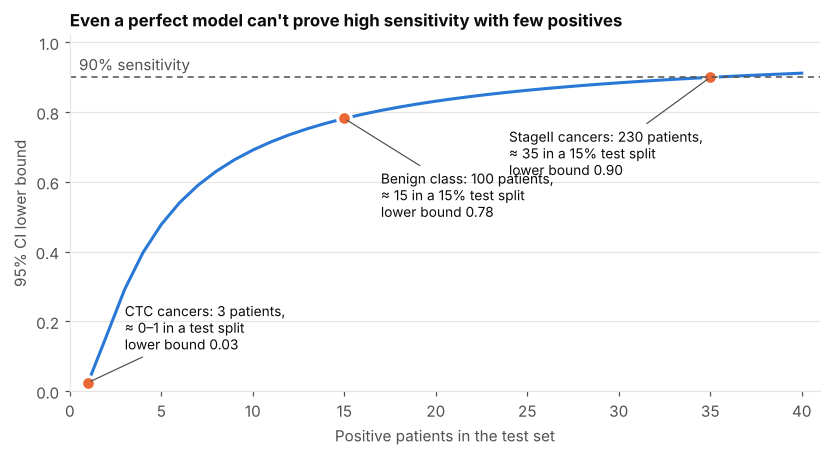

In [9]:
def cp_lower(k, n, alpha=0.05): return 0.0 if k == 0 else beta.ppf(alpha / 2, k, n - k + 1)
ns = np.arange(1, 41)
fig, ax = plt.subplots(figsize=(8.8, 4.2))
ax.plot(ns, [cp_lower(n, n) for n in ns], color=BLUE, lw=2)
marks = [("CTC cancers: 3 patients,\n≈ 0–1 in a test split", 1, (3, 0.12)),
         ("Benign class: 100 patients,\n≈ 15 in a 15% test split", 15, (17, 0.50)),
         ("StageII cancers: 230 patients,\n≈ 35 in a 15% test split", 35, (24, 0.62))]
for lab, n, xy in marks:
    v = cp_lower(n, n); ax.plot([n], [v], "o", ms=9, color=ORANGE, mec=SURF, mew=2)
    ax.annotate(f"{lab}\nlower bound {v:.2f}", (n, v), xytext=xy, textcoords="data", color=INK, fontsize=9,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.axhline(0.9, color=MUTED, lw=1, ls=(0, (4, 3))); ax.text(0.5, 0.91, "90% sensitivity", color=MUTED, ha="left", va="bottom")
ax.set_xlim(0, 41); ax.set_ylim(0, 1.02); ax.set_xlabel("Positive patients in the test set"); ax.set_ylabel("95% CI lower bound")
ax.set_title("Even a perfect model can't prove high sensitivity with few positives"); tidy(ax, "y")
save(fig, "eda_07_ci_planning")

## Decisions this EDA supports (carry into §4.5 Limitations)
1. The two sources differ in ways a network can read directly (volume size, slice thickness, acquisition), so **class = source** must be tested, not assumed away (§4.4).
2. The CTC cancers (3) are the only cancers from the benign class's own source: hold them out as a **challenge set**.
3. Slice or region selection needs a radiologist or an automated colon step; the datasets give no lesion coordinates.
4. Keep size and location baselines next to the CNN results (cancers are the largest and right-sided).